In [33]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from timm.data import Mixup 
import matplotlib.pyplot as plt
import numpy as np

In [34]:
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762))
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762))
])

In [35]:
device = (
    "cuda" if torch.cuda.is_available()
    else "cpu"
)
print(f"Using device: {device}")

Using device: cuda


In [36]:
trainSet = torchvision.datasets.CIFAR100(root='./data',train=True,download=True,
                                          transform=transform_train)
trainLoader = torch.utils.data.DataLoader(trainSet,batch_size=128,
                                          shuffle=True,num_workers=2)
testSet = torchvision.datasets.CIFAR100(root='./data',train=False,download=True,
                                          transform=transform_test)
testLoader = torch.utils.data.DataLoader(testSet,batch_size=100,
                                         shuffle=False,num_workers=2)

classes = trainSet.classes

Files already downloaded and verified
Files already downloaded and verified


In [37]:
train_features_batch,train_labels_batch = next(iter(trainLoader))
train_features_batch.shape 

torch.Size([128, 3, 32, 32])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.897426..2.024258].


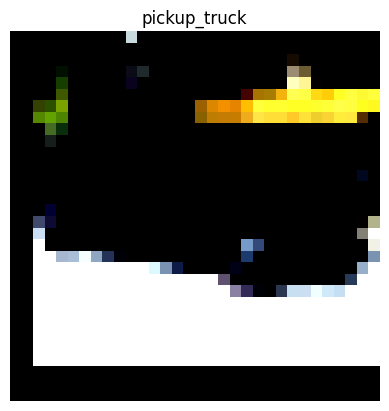

In [38]:
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]

plt.imshow(img.permute(1, 2, 0))   # (C,H,W) -> (H,W,C)
plt.title(classes[label])
plt.axis(False)
plt.show()

In [39]:
class BasicBlock(nn.Module):
    def __init__(self,in_channels,out_channels,stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=in_channels,out_channels=out_channels,stride=stride,kernel_size=3,padding=1,bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self,x):
        return self.relu((self.bn2(self.conv2(self.relu(self.bn1(self.conv1(x)))))) + self.shortcut(x))


In [40]:
class Resnet18(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        
        self.layer1 = self._make_layer(BasicBlock, 64, 2, stride=1)
        self.layer2 = self._make_layer(BasicBlock, 128, 2, stride=2)
        self.layer3 = self._make_layer(BasicBlock, 256, 2, stride=2)
        self.layer4 = self._make_layer(BasicBlock, 512, 2, stride=2)
        
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, block, out_channels, num_blocks, stride):
        strides = [stride] + [1]*(num_blocks-1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_channels, out_channels, stride))
            self.in_channels = out_channels
        return nn.Sequential(*layers)

    def forward(self,x):
        out = self.avgpool(self.layer4(self.layer3(self.layer2(self.layer1(self.relu(self.bn1(self.conv1(x))))))))
        out = out.view(out.size(0),-1)
        return self.fc(out)

In [41]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model = Resnet18().to(device)
model

Resnet18(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=

In [42]:
mixup_fn = Mixup(mixup_alpha=0.0, cutmix_alpha=1.0, prob=0.5,
                 label_smoothing=0.1, num_classes=100)
 
criterion = nn.CrossEntropyLoss()           

optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4, nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=0.1, epochs=100, steps_per_epoch=len(trainLoader))

In [43]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [44]:
def train_step(model:torch.nn.Module,
               train_dataloader: torch.utils.data.dataloader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device : torch.device = device):
    
    train_loss,train_acc = 0,0
    scaler = torch.amp.GradScaler()
    model.train()
    for batch,(X,y) in enumerate(train_dataloader):
        X, y = X.to(device), y.to(device)
        y_hard = y.clone()                    # keep hard labels for the accuracy metric
        X, y = mixup_fn(X, y)                 # CutMix applied here, y becomes soft labels
        
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            y_pred = model(X)
            loss = loss_fn(y_pred, y)

        train_loss += loss.item()
        train_acc += accuracy_fn(y_hard,y_pred.argmax(dim=1))

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step() 

        if batch % 100 == 0:
            print(f"Looked at {batch*len(X)}/{len(train_dataloader.dataset)} samples.") 

    train_loss /= len(train_dataloader)
    train_acc /= len(train_dataloader)
    print(f'Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.3f}')
    return train_loss,train_acc

In [45]:
def test_step(model:torch.nn.Module,
               test_dataloader: torch.utils.data.dataloader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device : torch.device = device):

    test_loss, test_acc = 0,0
    model.eval()
    with torch.inference_mode():
        for X,y in test_dataloader:
            X,y = X.to(device),y.to(device)

            test_pred = model(X)
            test_labels = torch.argmax(test_pred,dim=1)
            test_acc += accuracy_fn(y,test_labels)
            test_loss += loss_fn(test_pred,y)

        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)
    
    print(f'Test Loss : {test_loss:.4f} | Test Acc : {test_acc:.3f}')
    return test_acc


In [46]:
from tqdm.auto import tqdm
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_losses, train_acc_list, test_acc_list = [], [], []
epochs=100
for epoch in tqdm(range(epochs)):
    print(f'Epoch : {epoch}\n')
    train_loss,train_acc = train_step(model,trainLoader,criterion,optimizer ,accuracy_fn,device)
    train_losses.append(train_loss)
    train_acc_list.append(train_acc)
    test_acc = test_step(model,testLoader,criterion,accuracy_fn,device)
    test_acc_list.append(test_acc)


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch : 0



Looked at 0/50000 samples.
Looked at 12800/50000 samples.
Looked at 25600/50000 samples.
Looked at 38400/50000 samples.
Train Loss: 4.0870 | Train Acc: 10.327
Test Loss : 3.3674 | Test Acc : 19.140
Epoch : 1

Looked at 0/50000 samples.
Looked at 12800/50000 samples.
Looked at 25600/50000 samples.
Looked at 38400/50000 samples.
Train Loss: 3.6490 | Train Acc: 19.614
Test Loss : 2.8608 | Test Acc : 28.730
Epoch : 2

Looked at 0/50000 samples.
Looked at 12800/50000 samples.
Looked at 25600/50000 samples.
Looked at 38400/50000 samples.
Train Loss: 3.3932 | Train Acc: 25.929
Test Loss : 2.6227 | Test Acc : 33.220
Epoch : 3

Looked at 0/50000 samples.
Looked at 12800/50000 samples.
Looked at 25600/50000 samples.
Looked at 38400/50000 samples.
Train Loss: 3.1763 | Train Acc: 31.381
Test Loss : 2.3426 | Test Acc : 39.610
Epoch : 4

Looked at 0/50000 samples.
Looked at 12800/50000 samples.
Looked at 25600/50000 samples.
Looked at 38400/50000 samples.
Train Loss: 3.0737 | Train Acc: 34.922
Test 

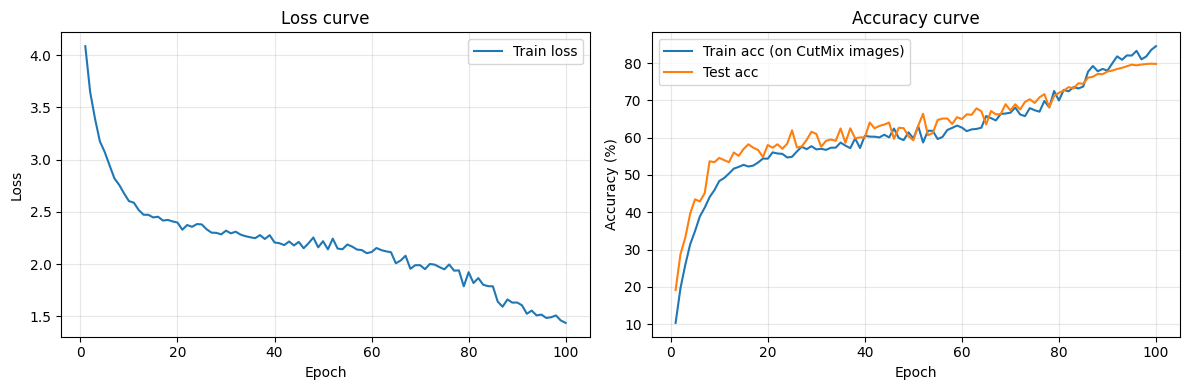

In [47]:
epochs_range = range(1, len(train_losses) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Loss
ax[0].plot(epochs_range, train_losses, label="Train loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].set_title("Loss curve")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Accuracy
ax[1].plot(epochs_range, train_acc_list, label="Train acc (on CutMix images)")
ax[1].plot(epochs_range, test_acc_list, label="Test acc")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy (%)")
ax[1].set_title("Accuracy curve")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()